# Mensagens adaptativas | Datathon MLET

**Grupo 10 | 7MLET** · Rafael Elias Ferreira Bergsten (rafaeleliasf@gmail.com)

Este notebook cobre a EDA, a preparação da base, a comparação entre baseline e bandit, o Golden Set
e o registro no MLflow. Instruções de execução, arquitetura AWS e governança estão no README.

A base Kaggle calibra taxas reais de conversão, mas não diz como os clientes reagiriam a cada
uma das três mensagens. Essas respostas são simuladas, como explicado na seção 3.

Ambiente: Python 3.12 com `requirements-lock.txt`. As 30 execuções levam alguns minutos.

## 1. Problema, ações e recompensa

O banco precisa escolher como apresentar uma oferta de depósito a prazo já aprovada.
As ações são três mensagens: **curta**, **explicação guiada** e **resumo de benefícios**.
O contexto é o tipo de contato, conhecido antes da escolha: `cellular` ou `telephone`.

A recompensa é 1 quando o cliente converte e 0 quando não converte.
Decisões sem resultado informado ficam pendentes na API.

In [1]:
import inspect
import json
import os
import sys
import tempfile
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.json').is_file() and (p / 'banditlab').is_dir())
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import Code, Image, Markdown, display

from banditlab.bandit import ACTIONS, CONTEXTS, ThompsonSampling
from banditlab.data import load_data, prepare_data
from banditlab.experiment import build_environment, run_experiments
from demo import golden_set

pd.set_option('display.max_columns', 12)
config = json.loads((root / 'config.json').read_text())
print('Python:', sys.version.split()[0])
print('Evaluation: semi-synthetic | Seeds:', config['repetitions'])

2026/09/29 22:40:59 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/rafaelelias/Projects/estudos/datathon-mlet/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Python: 3.12.4
Evaluation: semi-synthetic | Seeds: 30


## 2. Fonte, versão e preparação

[Bank Marketing no Kaggle](https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing),
versão 1, arquivo `bank-additional-full.csv`. Fonte original:
[Moro, Rita e Cortez, UCI, DOI 10.24432/C5K306](https://doi.org/10.24432/C5K306), licença CC BY 4.0.

O pipeline confere o SHA-256 do arquivo, mantém a ordem cronológica, converte `y` em 0/1 e
fica só com seis colunas. `duration` é descartada porque só existe depois da ligação.

In [2]:
if not (root / 'data/processed/bank_safe.csv').exists():
    prepare_data()
df = load_data()
manifest = json.loads((root / 'data/manifest.json').read_text())
display(pd.DataFrame([
    {'item': key, 'value': manifest[key]}
    for key in ['source', 'kaggle_version', 'rows', 'source_file', 'upstream_license', 'source_csv_sha256']
]))
display(pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'unique_values': df.nunique(),
}))
assert 'duration' not in df.columns
assert df.converted.isin([0, 1]).all()
assert not df.isna().any().any()

,item,value
0,source,https://www.kaggle.com/datasets/henriqueyamaha...
1,kaggle_version,1
2,rows,41188
3,source_file,bank-additional-full.csv
4,upstream_license,CC BY 4.0
5,source_csv_sha256,74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959...


,dtype,missing,unique_values
contact,str,0,2
month,str,0,10
day_of_week,str,0,5
previous,int64,0,8
poutcome,str,0,3
converted,int64,0,2


### Qualidade, categorias e redução de colunas

Em `poutcome`, `nonexistent` quer dizer que o cliente não participou de campanha anterior.
Valores ausentes ou alvo inválido interrompem o pipeline.
Linhas repetidas depois da redução de colunas foram mantidas, porque são contatos diferentes.

,metric,value
0,observations,41188.000000
1,conversion_rate,0.112654
2,identical_minimized_rows_not_removed,40268.000000


,observations,conversion
poutcome,,
failure,4252,0.142286
nonexistent,35563,0.088322
success,1373,0.651129


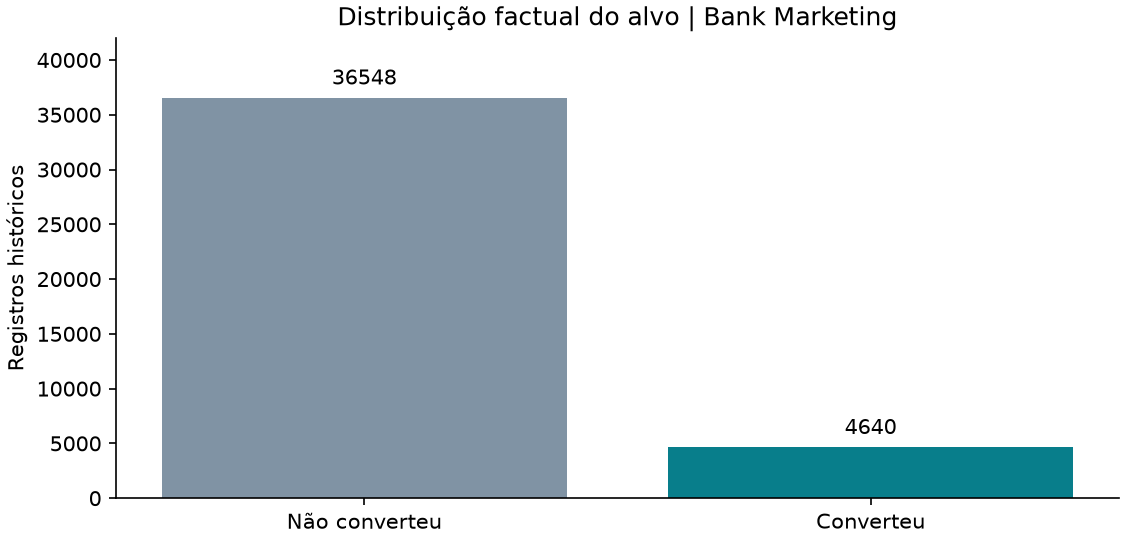

In [3]:
quality = pd.DataFrame([
    {'metric': 'observations', 'value': len(df)},
    {'metric': 'conversion_rate', 'value': df.converted.mean()},
    {'metric': 'identical_minimized_rows_not_removed', 'value': df.duplicated().sum()},
])
display(quality)
display(df.groupby('poutcome', observed=True).agg(observations=('converted', 'size'), conversion=('converted', 'mean')))

counts = df.converted.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout='constrained')
bars = ax.bar(['Não converteu', 'Converteu'], counts, color=['#8093A4', '#087E8B'])
ax.bar_label(bars, padding=4)
ax.set_title('Distribuição factual do alvo | Bank Marketing')
ax.set_ylabel('Registros históricos')
ax.set_ylim(0, counts.max() * 1.15)
ax.spines[['top', 'right']].set_visible(False)
(root / 'results').mkdir(exist_ok=True)
fig.savefig(root / 'results/eda_target.png', dpi=150)
display(Image(filename=str(root / 'results/eda_target.png')))
plt.close(fig)

### Conversão histórica por contato e ao longo do tempo

O celular converte bem mais que o telefone fixo, e a taxa muda bastante entre os períodos.
São associações: parte da diferença pode vir do perfil de público e da época, e não só do canal.
O alvo é desbalanceado (11,3% de conversão), o que reforça usar conversão, e não acurácia, como métrica.

In [4]:
display(df.groupby('contact', observed=True).agg(observations=('converted', 'size'), conversion=('converted', 'mean')))
display(df.groupby('month', observed=True).agg(observations=('converted', 'size'), conversion=('converted', 'mean')))

cut1 = int(len(df) * 0.6)
cut2 = int(len(df) * 0.8)
blocks = {'Primeiros 60%': df.iloc[:cut1], 'Próximos 20%': df.iloc[cut1:cut2], 'Últimos 20%': df.iloc[cut2:]}
temporal = pd.DataFrame([
    {'block': name, 'observations': len(block), 'conversion': block.converted.mean(),
     'cellular_share': block.contact.eq('cellular').mean()}
    for name, block in blocks.items()
])
display(temporal)
display(Markdown('**Leitura:** mudanças entre blocos reforçam a limitação de transportar taxas antigas para uma operação atual.'))

,observations,conversion
contact,,
cellular,26144,0.147376
telephone,15044,0.052313


,observations,conversion
month,,
apr,2632,0.204787
aug,6178,0.106021
dec,182,0.489011
jul,7174,0.090466
jun,5318,0.105115
mar,546,0.505495
may,13769,0.064347
nov,4101,0.101439
oct,718,0.438719


,block,observations,conversion,cellular_share
0,Primeiros 60%,24712,0.048074,0.455406
1,Próximos 20%,8238,0.110706,0.928017
2,Últimos 20%,8238,0.308327,0.879461


**Leitura:** mudanças entre blocos reforçam a limitação de transportar taxas antigas para uma operação atual.

## 3. Simulador

Os primeiros 60% da base calibram uma taxa de conversão por contexto, suavizada com Beta(1,1).
Cada mensagem multiplica essa taxa por um fator fixado no `config.json` antes dos experimentos.
O cenário principal tem metade do tráfego em cada contexto. O `observed_mix` usa a proporção de
contatos dos períodos mais recentes, e o `equal_arms` dá a mesma taxa às três mensagens.

Um piloto de 3.000 escolhas aleatórias serve de ponto de partida para todas as políticas.
Depois, cada execução avalia 20.000 decisões novas; as conversões do piloto não entram na conta.

In [5]:
environment = build_environment(df, config)
display(pd.DataFrame(config['assumed_message_multipliers'], index=CONTEXTS, columns=ACTIONS).rename_axis('Hypothetical multipliers'))
display(pd.DataFrame(environment['probabilities'], index=CONTEXTS, columns=ACTIONS).rename_axis('Simulated conversion probability'))
display(pd.DataFrame([environment['split_rows']]))
print('Held-out factual labels used to generate rewards:', environment['test_labels_used_for_rewards'])

,short_message,guided_explanation,benefits_summary
Hypothetical multipliers,,,
cellular,1.55,0.6,1.0
telephone,0.60,1.9,1.0


,short_message,guided_explanation,benefits_summary
Simulated conversion probability,,,
cellular,0.090472,0.035021,0.058369
telephone,0.023759,0.075238,0.039599


,train,validation,test
0,24712,8238,8238


Held-out factual labels used to generate rewards: False


## 4. Thompson Sampling

Cada contexto tem uma distribuição Beta por mensagem, começando em Beta(1,1) e atualizada com o piloto.
A cada decisão:

1. Sorteamos uma taxa de conversão de cada distribuição do contexto.
2. Escolhemos a mensagem com a maior taxa sorteada.
3. Observamos o resultado e atualizamos `alpha += reward` e `beta += 1 - reward`.

A classe abaixo é a mesma usada no experimento e na API.
Referência: [A Tutorial on Thompson Sampling, Russo et al.](https://arxiv.org/abs/1707.02038).

In [6]:
display(Code(inspect.getsource(ThompsonSampling), language='python'))

example_policy = ThompsonSampling(seed=42)
action = example_policy.select(context=0)
example_policy.update(context=0, action=action, reward=1)
print('Example selected action:', ACTIONS[action])
display(pd.DataFrame(example_policy.means, index=CONTEXTS, columns=ACTIONS))

class ThompsonSampling:
    def __init__(self, seed: int = 42, alpha=None, beta=None):
        self.rng = np.random.default_rng(seed)
        self.alpha = np.ones((2, 3)) if alpha is None else np.array(alpha, dtype=float)
        self.beta = np.ones((2, 3)) if beta is None else np.array(beta, dtype=float)
        if self.alpha.shape != (2, 3) or self.beta.shape != (2, 3):
            raise ValueError("Posterior arrays must have shape (2, 3)")
        if not (np.isfinite(self.alpha).all() and np.isfinite(self.beta).all()):
            raise ValueError("Posterior parameters must be finite")
        if (self.alpha <= 0).any() or (self.beta <= 0).any():
            raise ValueError("Posterior parameters must be positive")

    @property
    def means(self):
        return self.alpha / (self.alpha + self.beta)

    def select(self, context: int) -> int:
        samples = self.rng.beta(self.alpha[context], self.beta[context])
        return int(np.argmax(samples))

    def update(self, context: int, action: int, reward: int):
        if reward not in (0, 1):
            raise ValueError("Reward must be binary")
        self.alpha[context, action] += reward
        self.beta[context, action] += 1 - reward

    def state(self) -> dict:
        return {"alpha": self.alpha.tolist(), "beta": self.beta.tolist()}

Example selected action: benefits_summary


,short_message,guided_explanation,benefits_summary
cellular,0.5,0.5,0.666667
telephone,0.5,0.5,0.500000


## 5. Experimento e tracking

Comparamos a melhor mensagem única do piloto (baseline), a melhor mensagem por contexto,
Epsilon-Greedy com epsilon=0,10 e Thompson Sampling. O oráculo conhece as probabilidades
do simulador e mostra o teto possível.

As sementes vão de 42 a 71. Em cada uma, todas as políticas recebem os mesmos clientes e resultados
possíveis, mas cada uma só vê o resultado da mensagem que escolheu. A API usa a política da semente 42.

Esta célula refaz tudo e cria os runs no MLflow local.

In [7]:
summary, comparisons = run_experiments()
display(summary.loc[summary.scenario.eq('contextual'), ['policy', 'conversion', 'ci_low', 'ci_high', 'expected_regret']])
display(comparisons)

Completed contextual: 30 seeds


Completed equal_arms: 30 seeds


Completed observed_mix: 30 seeds


,policy,conversion,ci_low,ci_high,expected_regret
0,epsilon_greedy,0.079785,0.079158,0.080398,58.746259
1,fixed,0.054607,0.053132,0.055833,553.150714
2,oracle,0.082645,0.081958,0.083320,0.000000
3,segmented,0.082645,0.081958,0.083320,0.000000
4,thompson,0.082263,0.081627,0.082877,7.611177


,scenario,baseline,gain_pp,ci_low_pp,ci_high_pp,relative_lift_percent,win_fraction
0,contextual,fixed,2.765667,2.637658,2.912854,50.647052,1.000000
1,contextual,segmented,-0.038167,-0.051667,-0.025667,-0.461815,0.100000
2,equal_arms,fixed,-0.025333,-0.092833,0.045338,-0.516287,0.400000
3,equal_arms,segmented,-0.009667,-0.068004,0.049175,-0.197635,0.533333
4,observed_mix,fixed,0.522000,0.495333,0.548667,6.330598,1.000000
5,observed_mix,segmented,0.031500,-0.018004,0.089667,0.360570,0.266667


### Métricas e intervalos

Conversão é `conversões / decisões`, e o ganho é a diferença em pontos percentuais.
O arrependimento soma, a cada decisão, quanto se perdeu em relação à melhor mensagem possível.
Os intervalos de 95% vêm de bootstrap (5.000 reamostragens) sobre as médias das 30 execuções,
usando diferenças pareadas para o ganho.

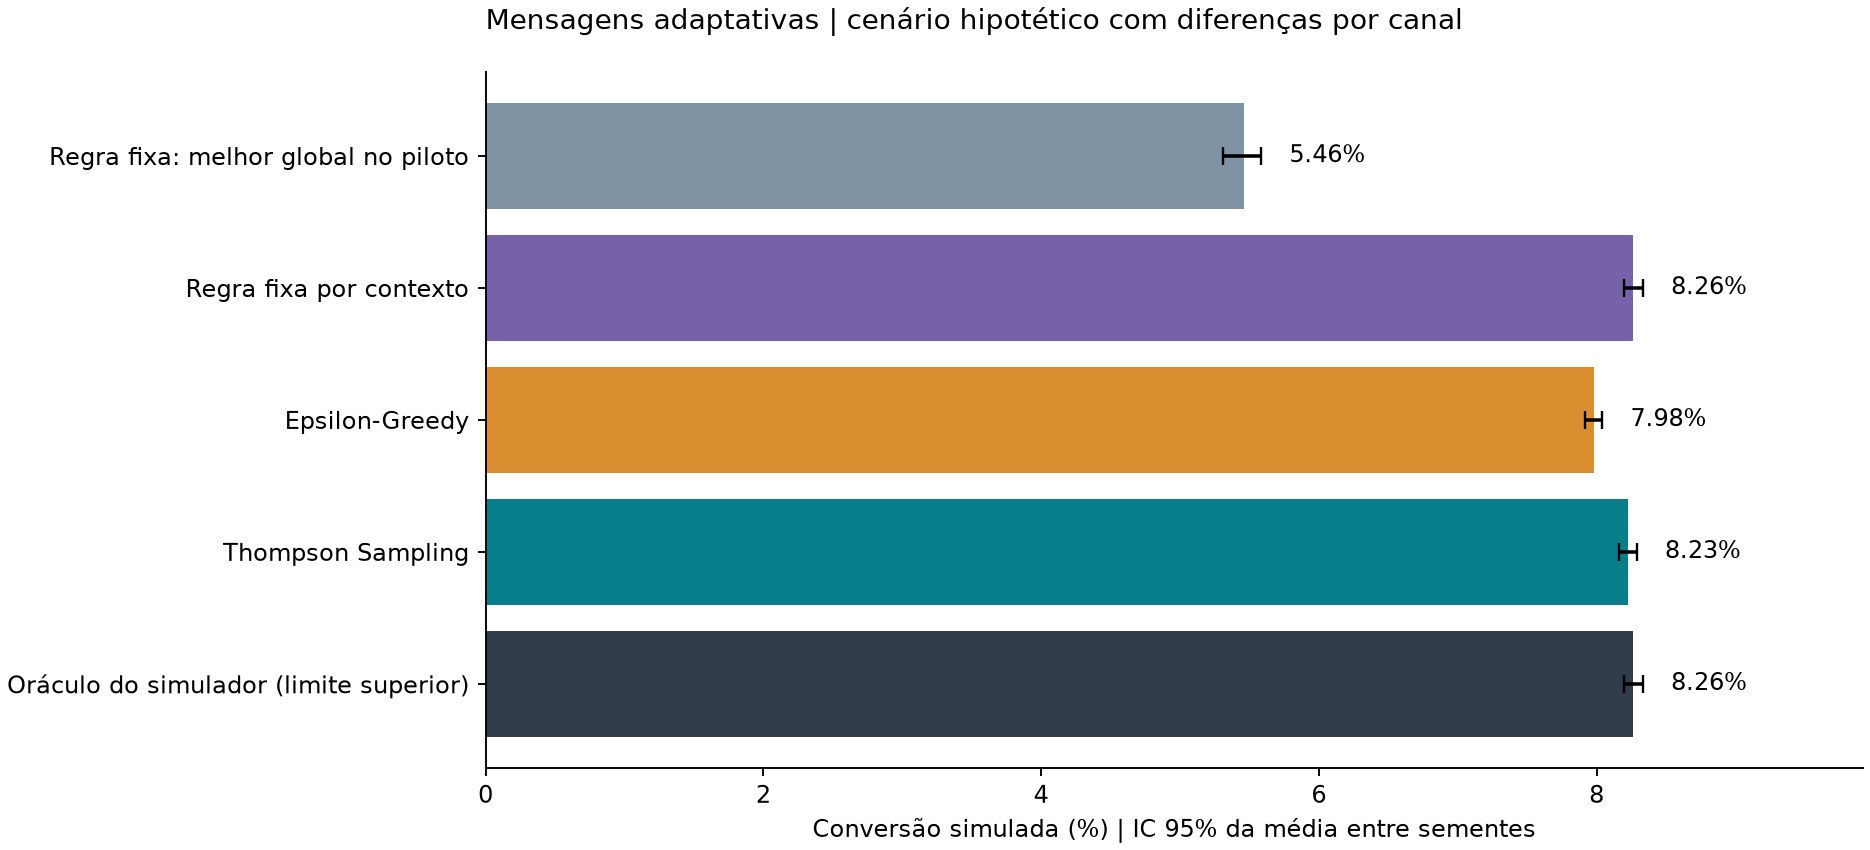

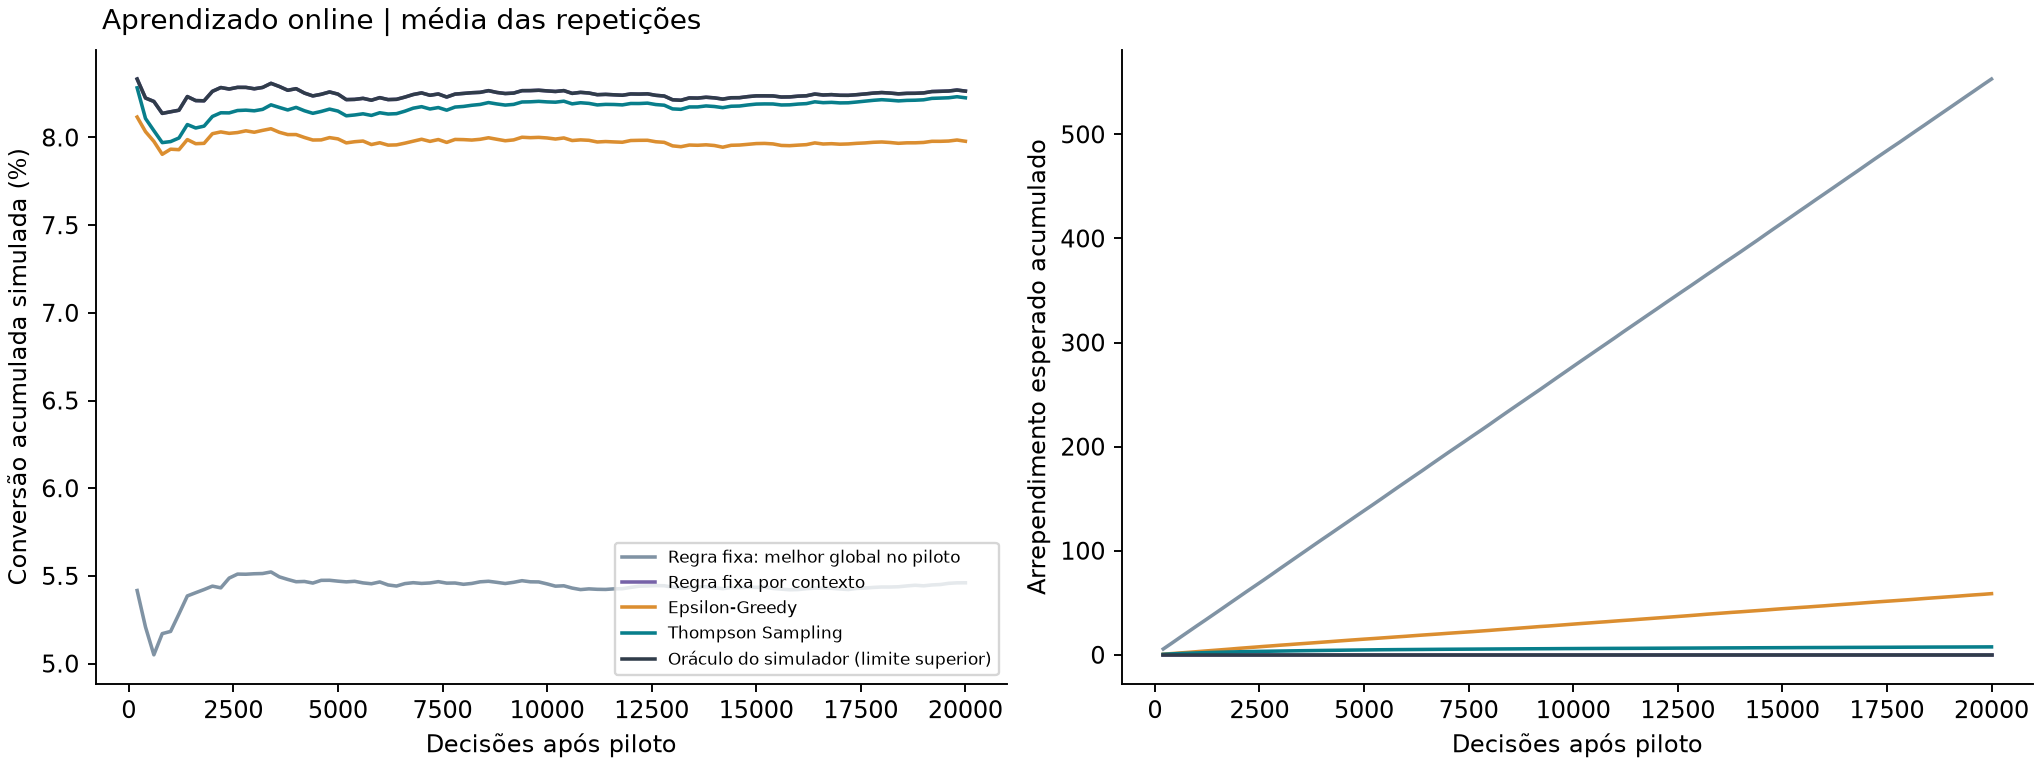

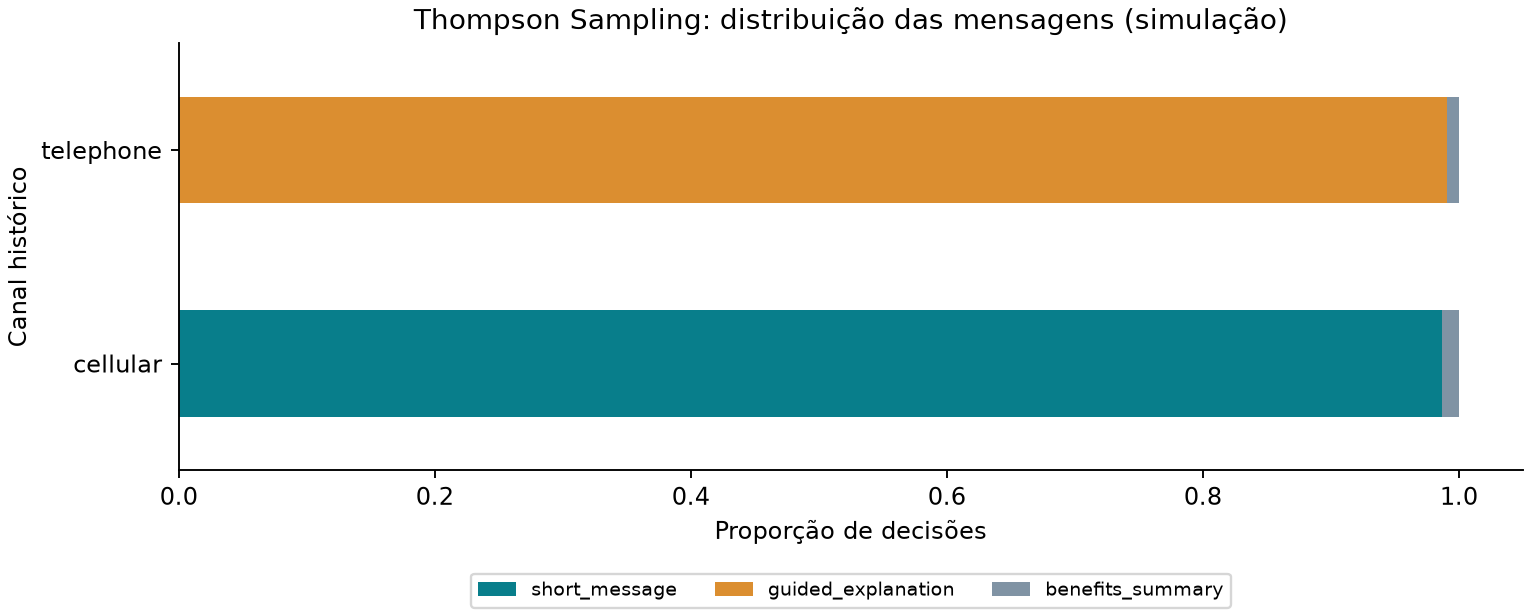

**Resultado simulado:** ganho médio de 2.766 p.p. contra mensagem única (IC 95% [2.638; 2.913]). Contra a segmentação fixa: -0.038 p.p. A política adaptativa não precisa vencer uma segmentação que já conhece bons braços em um ambiente estável.

In [8]:
display(Image(filename=str(root / 'results/comparison.png')))
display(Image(filename=str(root / 'results/learning.png')))
display(Image(filename=str(root / 'results/allocation.png')))

main = comparisons.query("scenario == 'contextual' and baseline == 'fixed'").iloc[0]
segmented = comparisons.query("scenario == 'contextual' and baseline == 'segmented'").iloc[0]
display(Markdown(
    f"**Resultado simulado:** ganho médio de {main.gain_pp:.3f} p.p. contra mensagem única "
    f"(IC 95% [{main.ci_low_pp:.3f}; {main.ci_high_pp:.3f}]). "
    f"Contra a segmentação fixa: {segmented.gain_pp:.3f} p.p. "
    "A política adaptativa não precisa vencer uma segmentação que já conhece bons braços em um ambiente estável."
))

### Controle negativo e cenário com tráfego real

No `equal_arms` as três mensagens convertem igual, então nenhum método deveria ganhar,
e o resultado confirma isso. No `observed_mix` o ganho diminui, porque quase todo o tráfego é de celular.

In [9]:
display(comparisons.loc[comparisons.scenario.ne('contextual')])
metrics = pd.read_csv(root / 'results/metrics.csv')
assert metrics.loc[metrics.scenario.eq('equal_arms'), 'expected_regret'].eq(0).all()
assert len(metrics) == 3 * 5 * config['repetitions']
print('All scenarios and seeds are included:', len(metrics), 'policy evaluations')

,scenario,baseline,gain_pp,ci_low_pp,ci_high_pp,relative_lift_percent,win_fraction
2,equal_arms,fixed,-0.025333,-0.092833,0.045338,-0.516287,0.400000
3,equal_arms,segmented,-0.009667,-0.068004,0.049175,-0.197635,0.533333
4,observed_mix,fixed,0.522000,0.495333,0.548667,6.330598,1.000000
5,observed_mix,segmented,0.031500,-0.018004,0.089667,0.360570,0.266667


All scenarios and seeds are included: 450 policy evaluations


## 6. Golden Set: cinco clientes fictícios

Dois clientes recebem mensagem e três não recebem, por inelegibilidade, falta de permissão ou contexto desconhecido.
Usamos o modo `greedy` para o resultado ser reproduzível; no modo `sample` a API às vezes explora outra mensagem.

In [10]:
golden = golden_set()
(root / 'results/golden_set.json').write_text(json.dumps(golden, indent=2, ensure_ascii=False) + '\n')
golden_table = pd.DataFrame(golden)[['case', 'contact', 'eligible', 'consent', 'actual_action', 'actual_reason', 'passed', 'rationale']]
display(golden_table)
assert golden_table.passed.all()

,case,contact,eligible,consent,actual_action,actual_reason,passed,rationale
0,A,cellular,True,True,short_message,NaN,True,Mensagem curta é a melhor no cenário simulado ...
1,B,telephone,True,True,guided_explanation,NaN,True,Explicação guiada é a melhor no cenário simula...
2,C,cellular,False,True,NaN,ineligible,True,Cliente inelegível: nenhuma mensagem comercial...
3,D,telephone,True,False,NaN,no_consent,True,Sem permissão de contato: nenhuma mensagem com...
4,E,unknown,True,True,NaN,unknown_context,True,Contexto desconhecido: encaminhar para validaç...


## 7. API na prática

Aqui chamamos os endpoints da API com um banco temporário, sem afetar o estado da API local.
O feedback atualiza só a mensagem daquela decisão, e reenviar o mesmo resultado não conta duas vezes.
Para testar pela interface, rode `uvicorn banditlab.api:app --host 127.0.0.1 --port 8000` e abra `/docs`.

In [11]:
from fastapi.testclient import TestClient

from banditlab.api import create_app

with tempfile.TemporaryDirectory() as directory:
    with TestClient(create_app(Path(directory) / 'notebook.sqlite')) as client:
        recommendation = client.post('/recommend', json={
            'contact': 'cellular', 'eligible': True, 'consent': True, 'mode': 'greedy'
        }).json()
        display(recommendation)
        event = {'decision_id': recommendation['decision_id'], 'reward': 1}
        display(client.post('/feedback', json=event).json())
        display(client.post('/feedback', json=event).json())
        display(client.get('/metrics').json())
        blocked = client.post('/recommend', json={
            'contact': 'telephone', 'eligible': True, 'consent': False
        }).json()
        assert blocked['action'] is None
        display(blocked)

/Users/rafaelelias/Projects/estudos/datathon-mlet/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'recommended',
 'decision_id': '48f35812-4b6f-43ea-b0da-92edcc3d49a2',
 'action': 'short_message',
 'message': 'Conheça a oferta de depósito a prazo e consulte as condições.',
 'contact': 'cellular',
 'mode': 'greedy',
 'posterior_mean': 0.0907675843953692,
 'model_version': 'ea6c30c6a053b096',
 'training_kind': 'semi_synthetic'}

{'status': 'recorded'}

{'status': 'already_recorded'}

{'decisions': 1,
 'feedback_received': 1,
 'conversions': 1,
 'pending_feedback': 0,
 'conversion_among_finalized': 1.0,
 'allocation': {'short_message': 1},
 'window': 'retained_events_only',
 'model_version': 'ea6c30c6a053b096',
 'http_requests_since_start': 3,
 'http_errors_since_start': 0,
 'mean_latency_ms_since_start': 1.8536530163449545}

{'status': 'withheld',
 'reason': 'no_consent',
 'action': None,
 'message': None,
 'decision_id': None,
 'model_version': 'ea6c30c6a053b096',
 'training_kind': 'semi_synthetic'}

## 8. MLflow

O run pai guarda parâmetros, hashes, ganhos, código-fonte e a política; os 450 runs filhos guardam
uma combinação de cenário, política e semente cada. O banco é o `mlflow.db`, com artefatos em `mlartifacts/`.

In [12]:
tracking = json.loads((root / 'results/tracking.json').read_text())
mlflow.set_tracking_uri(f"sqlite:///{root / 'mlflow.db'}")
client = mlflow.tracking.MlflowClient()
parent = client.get_run(tracking['parent_run_id'])
display(pd.DataFrame([{'parent_run_status': parent.info.status, 'child_runs': len(tracking['child_runs']),
                       'evaluation_kind': parent.data.tags['evaluation'],
                       'simulation_version': parent.data.params['simulation_version']}]))
assert parent.info.status == 'FINISHED'
assert len(tracking['child_runs']) == 450
display(pd.DataFrame([{'parameter': k, 'value': v} for k, v in parent.data.params.items()]))

,parent_run_status,child_runs,evaluation_kind,simulation_version
0,FINISHED,450,semi_synthetic,messages-v1


,parameter,value
0,steps,20000
1,repetitions,30
2,pilot_steps,3000
3,epsilon,0.1
4,prior,"Beta(1,1)"
5,first_seed,42
6,dataset_sha256,74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959...
7,code_sha256,bdf3ae524eb75d7ad535cebb21541dbbd8726a552fdc5b...
8,simulation_version,messages-v1


## 9. Conclusão

O pipeline baixa e prepara a base, compara políticas de forma reproduzível, registra tudo no MLflow
e serve recomendações com feedback. O Golden Set cobre os casos de elegibilidade, permissão e contexto desconhecido.

No simulador, escolher a mensagem por contexto converte bem mais que uma mensagem única, e o Thompson Sampling
chega perto do máximo possível. A regra fixa por contexto empata com ele num cenário estável.
As limitações estão na seção 8 do README.